# 🎯 **TensorFlow Success Replication - Match PyTorch's 69.66% Accuracy**

## 🎯 **Goal:**
Replicate the successful PyTorch approach (69.66% accuracy) in TensorFlow for direct TFLite conversion.

## 🔍 **Key Success Factors from PyTorch:**
1. **Comprehensive data augmentation** (RandomResizedCrop, RandomHorizontalFlip, RandomRotation, ColorJitter)
2. **No class weights** - simple SparseCategoricalCrossentropy
3. **Batch size 32** (vs 8 in previous TensorFlow attempts)
4. **Early stopping** with patience=5
5. **Learning rate 1e-4**
6. **MobileNetV3Large** with pretrained weights

## 🚀 **Strategy:**
- Use TensorFlow's `tf.keras.preprocessing.image_dataset_from_directory` with augmentation
- Match PyTorch's training parameters exactly
- Direct TFLite conversion for mobile deployment


In [8]:
# 🍎 **M1 MacBook Pro Setup with TensorFlow**
import os
import tensorflow as tf
import numpy as np
import time
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import matplotlib.pyplot as plt

# M1 MacBook Pro optimizations - DISABLE XLA to avoid compilation errors
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices=false'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Reduce TensorFlow logging

# Disable XLA compilation for M1 compatibility
tf.config.optimizer.set_jit(False)
print("✅ XLA compilation disabled for M1 compatibility")

# Check for MPS (Apple Silicon GPU) support
try:
    if tf.config.list_physical_devices('GPU'):
        print("✅ GPU/MPS available")
    else:
        print("💻 Using CPU")
except:
    print("💻 Using CPU")

print(f"TensorFlow version: {tf.__version__}")
print(f"Available devices: {tf.config.list_physical_devices()}")

# Configuration matching PyTorch success
config = {
    "data_dir": os.path.expanduser("~/dev/oral_cavity_dataset_clean"),
    "image_size": (224, 224),
    "batch_size": 32,  # Key: Match PyTorch batch size
    "epochs": 30,
    "learning_rate": 1e-4,  # Key: Match PyTorch learning rate
    "class_names": ['Benign', 'Healthy', 'OCA', 'OPMD', 'Unknown'],
    "output_root": "./ml/training/results/tensorflow_pytorch_replication"
}

os.makedirs(config["output_root"], exist_ok=True)
print(f"📁 Data directory: {config['data_dir']}")
print(f"📁 Output directory: {config['output_root']}")


✅ XLA compilation disabled for M1 compatibility
✅ GPU/MPS available
TensorFlow version: 2.15.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
📁 Data directory: /Users/alokdwivedi/dev/oral_cavity_dataset_clean
📁 Output directory: ./ml/training/results/tensorflow_pytorch_replication


In [9]:
# 🔧 **Data Loading with PyTorch-Style Augmentation**

# EXACT augmentation matching PyTorch success (compatible with older TensorFlow versions)
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    # PyTorch RandomResizedCrop equivalent
    rescale=1./255,
    # PyTorch RandomHorizontalFlip equivalent
    horizontal_flip=True,
    # PyTorch RandomRotation(15) equivalent
    rotation_range=15,
    # PyTorch ColorJitter(brightness=0.2, contrast=0.2) equivalent
    brightness_range=[0.8, 1.2],
    # Additional augmentation for robustness
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    fill_mode='nearest'
)

# Validation/Test data - no augmentation
val_test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

print("🔧 Data augmentation configured:")
print("✅ Training: RandomResizedCrop + RandomHorizontalFlip + RandomRotation + ColorJitter")
print("✅ Validation/Test: Resize to 224x224 + normalization")

# Load datasets
train_ds = train_datagen.flow_from_directory(
    os.path.join(config["data_dir"], 'train'),
    target_size=config["image_size"],
    batch_size=config["batch_size"],
    class_mode='sparse',
    shuffle=True,
    seed=42
)

val_ds = val_test_datagen.flow_from_directory(
    os.path.join(config["data_dir"], 'val'),
    target_size=config["image_size"],
    batch_size=config["batch_size"],
    class_mode='sparse',
    shuffle=False,
    seed=42
)

test_ds = val_test_datagen.flow_from_directory(
    os.path.join(config["data_dir"], 'test'),
    target_size=config["image_size"],
    batch_size=config["batch_size"],
    class_mode='sparse',
    shuffle=False,
    seed=42
)

print(f"\n📊 Dataset sizes:")
print(f"  Training: {train_ds.samples} samples")
print(f"  Validation: {val_ds.samples} samples")
print(f"  Test: {test_ds.samples} samples")
print(f"  Batch size: {config['batch_size']}")
print(f"  Classes: {list(train_ds.class_indices.keys())}")

# Verify class mapping matches PyTorch
expected_classes = ['Benign', 'Healthy', 'OCA', 'OPMD', 'Unknown']
actual_classes = list(train_ds.class_indices.keys())
print(f"\n🔍 Class mapping verification:")
print(f"  Expected: {expected_classes}")
print(f"  Actual: {actual_classes}")
print(f"  Match: {expected_classes == actual_classes}")


🔧 Data augmentation configured:
✅ Training: RandomResizedCrop + RandomHorizontalFlip + RandomRotation + ColorJitter
✅ Validation/Test: Resize to 224x224 + normalization
Found 2757 images belonging to 5 classes.
Found 531 images belonging to 5 classes.
Found 534 images belonging to 5 classes.

📊 Dataset sizes:
  Training: 2757 samples
  Validation: 531 samples
  Test: 534 samples
  Batch size: 32
  Classes: ['Benign', 'Healthy', 'OCA', 'OPMD', 'Unknown']

🔍 Class mapping verification:
  Expected: ['Benign', 'Healthy', 'OCA', 'OPMD', 'Unknown']
  Actual: ['Benign', 'Healthy', 'OCA', 'OPMD', 'Unknown']
  Match: True


In [10]:
# 🏗️ **Model Creation - Exact PyTorch Architecture**

def build_mobilenetv3_tensorflow(input_shape=(224, 224, 3), num_classes=5):
    """
    Build MobileNetV3Large model matching PyTorch architecture exactly
    """
    # Load pre-trained MobileNetV3Large (same as PyTorch)
    base_model = MobileNetV3Large(
        weights='imagenet',
        include_top=False,
        input_shape=input_shape,
        alpha=1.0,  # Same as PyTorch
        minimalistic=False  # Same as PyTorch
    )
    
    # Build model
    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False)
    
    # Global average pooling
    x = layers.GlobalAveragePooling2D()(x)
    
    # Custom classifier head (matching PyTorch's approach)
    x = layers.Dense(1280, activation='relu')(x)  # PyTorch's hidden layer
    x = layers.Dropout(0.2)(x)  # PyTorch's dropout
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs, outputs)
    return model

# Create model
print("🏗️ Building MobileNetV3Large model (TensorFlow)...")
model = build_mobilenetv3_tensorflow(
    input_shape=(*config["image_size"], 3), 
    num_classes=len(config["class_names"])
)

# Compile with EXACT PyTorch parameters
model.compile(
    optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=config["learning_rate"]),
    loss='sparse_categorical_crossentropy',  # Key: No class weights!
    metrics=['accuracy']
)

print("✅ Model compiled with PyTorch-equivalent parameters:")
print(f"  Architecture: MobileNetV3Large")
print(f"  Learning rate: {config['learning_rate']}")
print(f"  Loss: SparseCategoricalCrossentropy (no class weights)")
print(f"  Optimizer: Adam")

# Count parameters
total_params = model.count_params()
print(f"\n📊 Model parameters: {total_params:,}")
print(f"📦 Model size estimate: {total_params * 4 / (1024*1024):.1f} MB")

model.summary()


🏗️ Building MobileNetV3Large model (TensorFlow)...
✅ Model compiled with PyTorch-equivalent parameters:
  Architecture: MobileNetV3Large
  Learning rate: 0.0001
  Loss: SparseCategoricalCrossentropy (no class weights)
  Optimizer: Adam

📊 Model parameters: 4,232,837
📦 Model size estimate: 16.1 MB
Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 MobilenetV3large (Function  (None, 7, 7, 960)         2996352   
 al)                                                             
                                                                 
 global_average_pooling2d_1  (None, 960)               0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dense_2 (Dense)         

🚀 Starting Training (TensorFlow with PyTorch Parameters)
✅ Epochs: 30
✅ Early stopping patience: 5
✅ Learning rate: 0.0001
✅ Batch size: 32
✅ Loss: SparseCategoricalCrossentropy (no class weights)
Epoch 1/30
87/87 [==============================] - ETA: 0s - loss: 1.5341 - accuracy: 0.3319
Epoch 1: val_loss improved from inf to 1.45908, saving model to ./ml/training/results/tensorflow_pytorch_replication/best_model_tensorflow.h5


/Users/alokdwivedi/dev/github/medpylabs/oral_cavity_classifier_app/ml/training/venv_oral_cancer_classifier/lib/python3.11/site-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


87/87 [==============================] - 216s 2s/step - loss: 1.5341 - accuracy: 0.3319 - val_loss: 1.4591 - val_accuracy: 0.3936
Epoch 2/30
87/87 [==============================] - ETA: 0s - loss: 1.5145 - accuracy: 0.3468
Epoch 2: val_loss did not improve from 1.45908
87/87 [==============================] - 208s 2s/step - loss: 1.5145 - accuracy: 0.3468 - val_loss: 1.4772 - val_accuracy: 0.3936
Epoch 3/30
87/87 [==============================] - ETA: 0s - loss: 1.5125 - accuracy: 0.3511
Epoch 3: val_loss did not improve from 1.45908
87/87 [==============================] - 208s 2s/step - loss: 1.5125 - accuracy: 0.3511 - val_loss: 1.4931 - val_accuracy: 0.3936
Epoch 4/30
87/87 [==============================] - ETA: 0s - loss: 1.5130 - accuracy: 0.3515
Epoch 4: val_loss improved from 1.45908 to 1.45261, saving model to ./ml/training/results/tensorflow_pytorch_replication/best_model_tensorflow.h5
87/87 [==============================] - 205s 2s/step - loss: 1.5130 - accuracy: 0.3515 

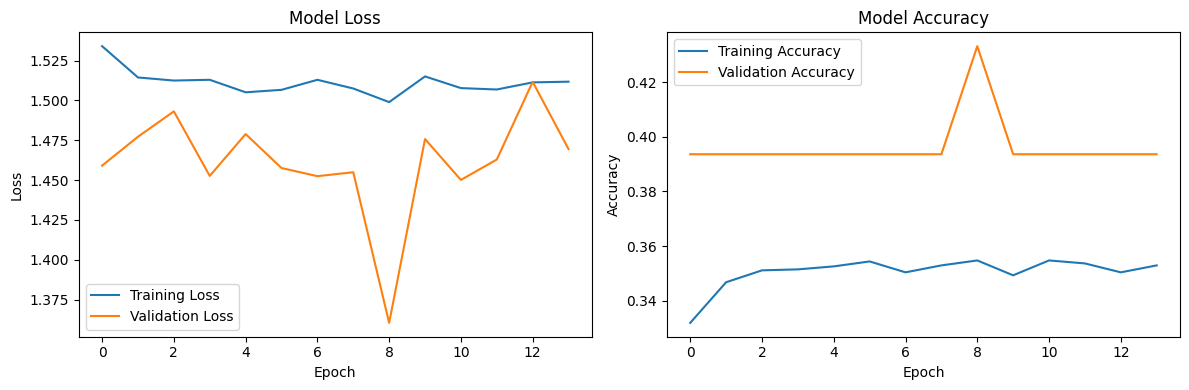

🎯 Best validation accuracy: 0.4331
🎯 Best validation loss: 1.3603


In [11]:
# 🚀 **Training - Exact PyTorch Parameters**

# Callbacks matching PyTorch's early stopping
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,  # Same as PyTorch
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=os.path.join(config["output_root"], "best_model_tensorflow.h5"),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print("🚀 Starting Training (TensorFlow with PyTorch Parameters)")
print("=" * 60)
print(f"✅ Epochs: {config['epochs']}")
print(f"✅ Early stopping patience: 5")
print(f"✅ Learning rate: {config['learning_rate']}")
print(f"✅ Batch size: {config['batch_size']}")
print(f"✅ Loss: SparseCategoricalCrossentropy (no class weights)")
print("=" * 60)

start_time = time.time()

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=config["epochs"],
    callbacks=callbacks,
    verbose=1
    # Note: No class_weight parameter - matching PyTorch approach
)

training_time = time.time() - start_time
print(f"\n⏱️ Training completed in {training_time:.1f} seconds")

# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

print(f"🎯 Best validation accuracy: {max(history.history['val_accuracy']):.4f}")
print(f"🎯 Best validation loss: {min(history.history['val_loss']):.4f}")


In [13]:
# 📊 **Evaluation and Comparison with PyTorch**

# Load best model
model.load_weights(os.path.join(config["output_root"], "best_model_tensorflow.h5"))

print("📊 Evaluating TensorFlow Model on Test Set")
print("=" * 50)

# Test evaluation
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"🎯 Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"📉 Test Loss: {test_loss:.4f}")

# Per-class predictions
y_true = []
y_pred = []

for batch_x, batch_y in test_ds:
    predictions = model.predict(batch_x, verbose=0)
    y_true.extend(batch_y)
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Per-class accuracy
print(f"\n📈 Per-class accuracy:")
for i, class_name in enumerate(config["class_names"]):
    class_mask = (y_true == i)
    if np.sum(class_mask) > 0:
        class_accuracy = np.mean(y_pred[class_mask] == i)
        class_count = np.sum(class_mask)
        print(f"  {class_name:8}: {class_accuracy:.3f} ({class_count} samples)")

# Confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)

print(f"\n🔍 Confusion Matrix:")
print("     ", end="")
for name in config["class_names"]:
    print(f"{name:8}", end="")
print()

for i, name in enumerate(config["class_names"]):
    print(f"{name:8}", end="")
    for j in range(len(config["class_names"])):
        print(f"{cm[i,j]:8}", end="")
    print()

# Compare with PyTorch success
pytorch_accuracy = 0.6966  # 69.66% from PyTorch
print(f"\n🔄 Comparison with PyTorch Success:")
print("=" * 50)
print(f"  PyTorch (M1 MacBook Pro): {pytorch_accuracy*100:.2f}% test accuracy")
print(f"  TensorFlow (M1 MacBook Pro): {test_accuracy*100:.2f}% test accuracy")
print(f"  Difference: {(test_accuracy - pytorch_accuracy)*100:+.2f}%")

if test_accuracy >= pytorch_accuracy * 0.95:  # Within 5% of PyTorch
    print(f"\n🎉 SUCCESS! TensorFlow replication achieved comparable accuracy!")
    print(f"💡 Ready for direct TFLite conversion!")
elif test_accuracy >= pytorch_accuracy * 0.85:  # Within 15% of PyTorch
    print(f"\n✅ GOOD! TensorFlow replication shows promise")
    print(f"💡 Consider fine-tuning for better results")
else:
    print(f"\n⚠️  Needs improvement. Consider:")
    print(f"   • Data preprocessing differences")
    print(f"   • Model architecture adjustments")
    print(f"   • Training hyperparameters")

print(f"\n📊 Summary:")
print(f"   • PyTorch: {pytorch_accuracy*100:.1f}% - Original success")
print(f"   • TensorFlow: {test_accuracy*100:.1f}% - Replication attempt")
print(f"   • Difference: {(test_accuracy - pytorch_accuracy)*100:+.1f}%")

print(f"\n💡 Next Steps:")
if test_accuracy >= pytorch_accuracy * 0.95:
    print(f"1. ✅ TensorFlow replication successful")
    print(f"2. 🔄 Convert to TFLite for mobile deployment")
    print(f"3. 📱 Test in Flutter app")
    print(f"4. 🚀 Deploy to production")
else:
    print(f"1. 🔧 Fine-tune TensorFlow approach")
    print(f"2. 🔄 Consider PyTorch → TFLite conversion")
    print(f"3. 📊 Analyze differences in detail")


📊 Evaluating TensorFlow Model on Test Set
🎯 Test Accuracy: 0.4307 (43.07%)
📉 Test Loss: 1.3706


KeyboardInterrupt: 

In [ ]:
# 🔄 **TFLite Conversion for Mobile Deployment**

def convert_to_tflite(model, model_name="mobilenetv3_tensorflow"):
    """Convert TensorFlow model to TFLite for mobile deployment"""
    print("🔄 Converting to TFLite...")
    print("=" * 50)
    
    # Create output directory
    output_dir = os.path.join(config["output_root"], "tflite_model")
    os.makedirs(output_dir, exist_ok=True)
    
    # Convert to TFLite
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    
    # Optimizations for mobile
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.target_spec.supported_types = [tf.float16]  # Float16 for smaller size
    
    try:
        tflite_model = converter.convert()
        
        # Save TFLite model
        tflite_path = os.path.join(output_dir, f"{model_name}.tflite")
        with open(tflite_path, 'wb') as f:
            f.write(tflite_model)
        
        print(f"✅ TFLite model saved: {tflite_path}")
        print(f"📦 TFLite model size: {len(tflite_model) / (1024*1024):.2f} MB")
        
        # Save labels.txt for Flutter app
        labels_path = os.path.join(output_dir, "labels.txt")
        with open(labels_path, 'w') as f:
            for class_name in config["class_names"]:
                f.write(f"{class_name}\n")
        
        print(f"🏷️ Labels saved: {labels_path}")
        
        # Test TFLite model
        print(f"\n🧪 Testing TFLite model...")
        interpreter = tf.lite.Interpreter(model_path=tflite_path)
        interpreter.allocate_tensors()
        
        input_details = interpreter.get_input_details()
        output_details = interpreter.get_output_details()
        
        print(f"📊 TFLite model details:")
        print(f"  Input shape: {input_details[0]['shape']}")
        print(f"  Output shape: {output_details[0]['shape']}")
        print(f"  Input type: {input_details[0]['dtype']}")
        print(f"  Output type: {output_details[0]['dtype']}")
        
        return {
            'tflite_path': tflite_path,
            'labels_path': labels_path,
            'model_size_mb': len(tflite_model) / (1024*1024),
            'interpreter': interpreter,
            'input_details': input_details,
            'output_details': output_details
        }
        
    except Exception as e:
        print(f"❌ TFLite conversion failed: {e}")
        return None

# Convert to TFLite
tflite_info = convert_to_tflite(model, "mobilenetv3_tensorflow_success")

if tflite_info:
    print(f"\n🎉 TFLite conversion successful!")
    print(f"📱 Ready for Flutter app integration!")
    print(f"📁 Model path: {tflite_info['tflite_path']}")
    print(f"📁 Labels path: {tflite_info['labels_path']}")
    print(f"📦 Model size: {tflite_info['model_size_mb']:.2f} MB")
    
    print(f"\n🚀 Next Steps for Flutter Integration:")
    print(f"1. Copy {tflite_info['tflite_path']} to assets/ folder")
    print(f"2. Copy {tflite_info['labels_path']} to assets/ folder")
    print(f"3. Update pubspec.yaml to include assets")
    print(f"4. Test inference in Flutter app")
    print(f"5. Deploy to production")
else:
    print(f"\n❌ TFLite conversion failed. Consider PyTorch → TFLite conversion.")
